In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load the Dataset

In [2]:
import pandas as pd
import numpy as np

# Define the file path to your dataset in Google Drive
base_path = '/content/drive/MyDrive/UCI HAR Dataset/' # Add a trailing slash

# Load feature names
features = pd.read_csv(base_path + 'features.txt', header=None, delim_whitespace=True)
feature_names = features[1].values  # Get feature names as a list

# Load activity labels
activity_labels = pd.read_csv(base_path + 'activity_labels.txt', header=None, delim_whitespace=True)

# Load training and test data (signals, subjects, and activities)
X_train = pd.read_csv(base_path + 'train/X_train.txt', header=None, delim_whitespace=True)
y_train = pd.read_csv(base_path + 'train/y_train.txt', header=None, delim_whitespace=True)
subject_train = pd.read_csv(base_path + 'train/subject_train.txt', header=None, delim_whitespace=True)

X_test = pd.read_csv(base_path + 'test/X_test.txt', header=None, delim_whitespace=True)
y_test = pd.read_csv(base_path + 'test/y_test.txt', header=None, delim_whitespace=True)
subject_test = pd.read_csv(base_path + 'test/subject_test.txt', header=None, delim_whitespace=True)


<ipython-input-2-6f38601e0cd0>:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  features = pd.read_csv(base_path + 'features.txt', header=None, delim_whitespace=True)
<ipython-input-2-6f38601e0cd0>:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  activity_labels = pd.read_csv(base_path + 'activity_labels.txt', header=None, delim_whitespace=True)
<ipython-input-2-6f38601e0cd0>:15: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  X_train = pd.read_csv(base_path + 'train/X_train.txt', header=None, delim_whitespace=True)
<ipython-input-2-6f38601e0cd0>:16: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  y_trai

# Preprocessing the Dataset

In [3]:
# Assign feature names to the dataset
X_train.columns = feature_names
X_test.columns = feature_names

# Combine data into single dataframe (optional)
train_data = X_train.copy()
train_data['activity'] = y_train.values
train_data['subject'] = subject_train.values

test_data = X_test.copy()
test_data['activity'] = y_test.values
test_data['subject'] = subject_test.values

# Normalize the data (using z-score normalization)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Optionally, you can combine subject and activity data for full data view
y_train = y_train.values.flatten()
y_test = y_test.values.flatten()


# Synthetic Data Generation with GAN/ VAE:

In [4]:
from tensorflow.keras import layers, models
import numpy as np

# Define the generator model
def build_generator(latent_dim):
    model = models.Sequential()
    model.add(layers.Dense(128, input_dim=latent_dim, activation='relu'))
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dense(X_train_scaled.shape[1], activation='tanh'))  # Output layer
    return model

# Define the discriminator model
def build_discriminator(input_shape):
    model = models.Sequential()
    model.add(layers.Dense(512, input_dim=input_shape, activation='relu'))
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))  # Output layer (real/fake)
    return model

# Define the GAN model (combining the generator and discriminator)
def build_gan(generator, discriminator):
    discriminator.trainable = False
    model = models.Sequential()
    model.add(generator)
    model.add(discriminator)
    return model

# Initialize models
latent_dim = 100
generator = build_generator(latent_dim)
discriminator = build_discriminator(X_train_scaled.shape[1])
gan = build_gan(generator, discriminator)

# Compile models
discriminator.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gan.compile(optimizer='adam', loss='binary_crossentropy')

# Train the GAN
def train_gan(generator, discriminator, gan, X_train, epochs=1000, batch_size=128):
    half_batch = batch_size // 2
    for epoch in range(epochs):
        # Select a random batch of real data
        idx = np.random.randint(0, X_train.shape[0], half_batch)
        real_data = X_train[idx]

        # Generate a batch of fake data
        noise = np.random.normal(0, 1, (half_batch, latent_dim))
        fake_data = generator.predict(noise)

        # Train the discriminator
        d_loss_real = discriminator.train_on_batch(real_data, np.ones((half_batch, 1)))
        d_loss_fake = discriminator.train_on_batch(fake_data, np.zeros((half_batch, 1)))
        d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

        # Train the generator
        noise = np.random.normal(0, 1, (batch_size, latent_dim))
        g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))

        if epoch % 100 == 0:
            print(f"Epoch: {epoch}, D Loss: {d_loss[0]}, G Loss: {g_loss}")


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Generate Synthetic Data

In [5]:
noise = np.random.normal(0, 1, (y_train.shape[0], latent_dim))  # Generate samples to match y_train
generated_data = generator.predict(noise)
generated_data = scaler.inverse_transform(generated_data)  # If normalization was applied




230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


# Evaluate the Synthetic Data

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Train on real data
rf = RandomForestClassifier()
rf.fit(X_train_scaled, y_train)
real_accuracy = accuracy_score(y_test, rf.predict(X_test_scaled))

# Train on synthetic data
rf.fit(generated_data, y_train)  # Assuming synthetic labels are available
synthetic_accuracy = accuracy_score(y_test, rf.predict(X_test_scaled))

print(f"Real Data Accuracy: {real_accuracy}, Synthetic Data Accuracy: {synthetic_accuracy}")


Real Data Accuracy: 0.9243298269426535, Synthetic Data Accuracy: 0.166949440108585


# More Epochs and Batch Size
Training GAN

In [7]:
# Set the batch size and epochs to more manageable values
epochs = 1000  # Lower the epochs to 1000
batch_size = 64  # Reduce the batch size to 64

# Train the GAN with the new parameters
train_gan(generator, discriminator, gan, X_train_scaled, epochs=epochs, batch_size=batch_size)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch: 0, D Loss: 0.944908618927002, G Loss: 0.7660669088363647
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━

# Adjust Learning Rates

In [8]:
from tensorflow.keras.optimizers import Adam # Import the Adam optimizer

optimizer = Adam(learning_rate=0.0002, beta_1=0.5)  # Use learning_rate instead of lr

# Loss Plot

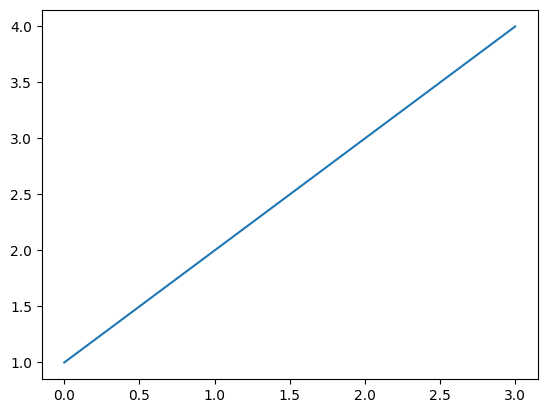

In [ ]:
import matplotlib.pyplot as plt
plt.plot([1, 2, 3, 4])
plt.show()


In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Generator Model
def build_generator(input_dim, output_dim):
    model = models.Sequential([
        layers.Dense(128, activation='relu', input_dim=input_dim),
        layers.Dense(256, activation='relu'),
        layers.Dense(output_dim, activation='tanh')  # Match real data shape
    ])
    return model

generator = build_generator(input_dim=100, output_dim=X_train.shape[1])
generator.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 128)                 │          12,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 561)                 │         144,177 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 190,129 (742.69 KB)

 Trainable params: 190,129 (742.69 KB)

 Non-trainable params: 0 (0.00 B)

# Discriminator Model

In [10]:
# Discriminator Model
def build_discriminator(input_dim):
    model = models.Sequential([
        layers.Dense(256, activation='relu', input_dim=input_dim),
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

discriminator = build_discriminator(input_dim=X_train.shape[1])
discriminator.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                     │ (None, 256)                 │         143,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 176,897 (691.00 KB)

 Trainable params: 176,897 (691.00 KB)

 Non-trainable params: 0 (0.00 B)

# GAN Training Process (Placeholder)

In [11]:
# Define GAN Training Logic (consistent with UCI HAR)
# Ensure synthetic data aligns with real data dimensionality and characteristics.


# GAN Training Code

In [12]:
import tensorflow as tf
from keras import backend as K
import psutil

# Reduce batch size
batch_size = 32  # Reduce if needed

# Enable memory growth for GPU
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)

# Function to print memory usage
def print_memory_usage():
    print(f"Memory Usage: {psutil.virtual_memory().percent}%")

# Add this inside your training loop (if needed)
# At the end of each epoch or after finishing training
K.clear_session()

# Optional: print memory usage
print_memory_usage()


Memory Usage: 16.8%


In [13]:
from keras.models import Sequential
from keras.layers import Dense, LeakyReLU, BatchNormalization

# Define the Generator model
def build_generator():
    model = Sequential()

    # First dense layer with input size 100 (random noise dimension)
    model.add(Dense(256, input_dim=100))
    model.add(LeakyReLU(0.2))
    model.add(BatchNormalization(momentum=0.8))

    # Second dense layer
    model.add(Dense(512))
    model.add(LeakyReLU(0.2))
    model.add(BatchNormalization(momentum=0.8))

    # Third dense layer
    model.add(Dense(1024))
    model.add(LeakyReLU(0.2))
    model.add(BatchNormalization(momentum=0.8))

    # Output layer (dimension should match the real data)
    model.add(Dense(561, activation='tanh'))  # 561 is the number of features in UCI HAR

    return model

# Instantiate the Generator
generator = build_generator()

# Display the generator architecture
generator.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │          25,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_1 (LeakyReLU)            │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1024)                │         525,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 561)                 │         575,025 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,264,945 (4.83 MB)

 Trainable params: 1,261,361 (4.81 MB)

 Non-trainable params: 3,584 (14.00 KB)

In [14]:
# Load training data (features only, without labels)
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"

# Load the data as pandas DataFrames with the updated separator
X_train = pd.read_csv(train_data_path, sep='\s+', header=None)
X_test = pd.read_csv(test_data_path, sep='\s+', header=None)

In [15]:
import pandas as pd

# Paths to the dataset
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"

# Load the dataset
X_train = pd.read_csv(train_data_path, sep='\s+', header=None)
X_test = pd.read_csv(test_data_path, sep='\s+', header=None)

# Combine training and test datasets (if needed)
real_data = pd.concat([X_train, X_test], axis=0).values  # Convert to NumPy array

print(f"real_data shape: {real_data.shape}")  # Verify the shape


real_data shape: (10299, 561)


In [16]:
from keras.models import Sequential
from keras.layers import Dense, LeakyReLU

# Define the Discriminator model
def build_discriminator(input_dim):
    model = Sequential()

    # First dense layer
    model.add(Dense(1024, input_dim=input_dim))
    model.add(LeakyReLU(0.2))

    # Second dense layer
    model.add(Dense(512))
    model.add(LeakyReLU(0.2))

    # Third dense layer
    model.add(Dense(256))
    model.add(LeakyReLU(0.2))

    # Output layer (binary classification: real or fake)
    model.add(Dense(1, activation='sigmoid'))

    return model

# Instantiate the Discriminator
discriminator = build_discriminator(real_data.shape[1])  # 561 features

# Display the discriminator architecture
discriminator.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 1024)                │         575,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_4 (LeakyReLU)            │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_5 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,231,873 (4.70 MB)

 Trainable params: 1,231,873 (4.70 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
from keras.layers import Input
from keras.models import Model

# Create the GAN by combining the generator and the discriminator
z = Input(shape=(100,))  # Define input for noise vector
generated_data = generator(z)

# GAN output is the discriminator's output for the generated data
validity = discriminator(generated_data)

# Build and compile the GAN model
gan = Model(z, validity)
gan.compile(loss='binary_crossentropy', optimizer=Adam(0.0002, 0.5))


In [18]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K
K.clear_session()

# Load data
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"

X_train = pd.read_csv(train_data_path, sep='\s+', header=None)
X_test = pd.read_csv(test_data_path, sep='\s+', header=None)
real_data = pd.concat([X_train, X_test], axis=0).values  # Convert to NumPy array

# Define the discriminator model
discriminator = Sequential()
discriminator.add(Input(shape=(561,)))  # Input layer with feature dimension
discriminator.add(Dense(512))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dense(1, activation='sigmoid'))

# Compile the discriminator model
discriminator.compile(loss='binary_crossentropy',
                      optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
                      metrics=['accuracy'])

# Define the generator model
generator = Sequential()
generator.add(Input(shape=(100,)))  # Explicit Input layer for noise dimension
generator.add(Dense(256))
generator.add(LeakyReLU(0.2))
generator.add(Dense(561, activation='tanh'))  # Output dimension matches real data

# Define GAN model by combining the generator and the discriminator
discriminator.trainable = False  # Freeze discriminator weights for GAN training
gan = Sequential()
gan.add(generator)
gan.add(discriminator)

# Compile the GAN model
gan.compile(loss='binary_crossentropy',
            optimizer=Adam(learning_rate=0.0002, beta_1=0.5))

# Define batch size and epochs
batch_size = 16
epochs = 500
sample_interval = 100

# Training loop for GAN
for epoch in range(epochs):
    # Train Discriminator
    idx = np.random.randint(0, real_data.shape[0], batch_size)
    real_samples = real_data[idx]

    noise = np.random.normal(0, 1, (batch_size, 100))
    fake_samples = generator.predict(noise, verbose=0)

    # Train discriminator on real and fake samples
    d_loss_real = discriminator.train_on_batch(real_samples, np.ones((batch_size, 1)))
    d_loss_fake = discriminator.train_on_batch(fake_samples, np.zeros((batch_size, 1)))
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)  # Average loss

    # Train Generator
    noise = np.random.normal(0, 1, (batch_size, 100))
    g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))

    # Output training progress
    if epoch % sample_interval == 0:
        # Safely extract loss values (avoid indexing issues)
        d_loss_val = d_loss[0] if isinstance(d_loss, (list, tuple, np.ndarray)) and len(d_loss) > 0 else float(d_loss)
        d_acc_val = d_loss[1] if isinstance(d_loss, (list, tuple, np.ndarray)) and len(d_loss) > 1 else 0.0
        g_loss_val = float(g_loss)  # Convert to float to ensure scalar handling

        print(f"Epoch: {epoch}, D Loss: {d_loss_val:.4f}, D Accuracy: {d_acc_val * 100:.2f}%, G Loss: {g_loss_val:.4f}")

# Save models to avoid retraining
generator.save('/content/drive/MyDrive/generator_model.h5')
discriminator.save('/content/drive/MyDrive/discriminator_model.h5')

/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch: 0, D Loss: 1.0877, D Accuracy: 34.38%, G Loss: 0.9479
Epoch: 100, D Loss: 2.1539, D Accuracy: 2.61%, G Loss: 0.1220
Epoch: 200, D Loss: 2.6599, D Accuracy: 1.70%, G Loss: 0.0653
Epoch: 300, D Loss: 2.9631, D Accuracy: 1.40%, G Loss: 0.0447
Epoch: 400, D Loss: 3.1850, D Accuracy: 1.36%, G Loss: 0.0341


In [19]:
# Save models to Google Drive
discriminator.save('/content/drive/MyDrive/discriminator_model.h5')
generator.save('/content/drive/MyDrive/generator_model.h5')


In [20]:
gan.save('/content/drive/MyDrive/gan_model.h5')


In [21]:
# Save variables to a file
np.save('/content/drive/MyDrive/real_data.npy', real_data)  # If real_data is large


In [22]:
# Create a dictionary or list to track progress and save it
training_progress = {'epochs': epoch, 'd_loss': d_loss, 'g_loss': g_loss}
np.save('/content/drive/MyDrive/training_progress.npy', training_progress)


In [23]:
# Save data results to CSV or NumPy
pd.DataFrame(real_data).to_csv('/content/drive/MyDrive/real_data.csv', index=False)


In [24]:
# Assuming real_data is loaded with shape (N, 561)
real_data = np.array(pd.read_csv('/content/drive/MyDrive/real_data.csv'))  # Replace with your actual data path

# Reduce or select the appropriate features for training
real_data_reduced = real_data[:, :561]  # Ensure it has 561 features as expected by the discriminator

# Define batch size and epochs
batch_size = 64
epochs = 500
sample_interval = 100  # Print every 100 epochs

# Training loop
for epoch in range(epochs):
    # Train discriminator
    idx = np.random.randint(0, real_data_reduced.shape[0], batch_size)
    real_samples = real_data_reduced[idx]  # Ensure real_samples shape matches discriminator input (batch_size, 561)
    noise = np.random.normal(0, 1, (batch_size, 100))  # Latent space for generator (100)
    fake_samples = generator.predict(noise, verbose=0)  # Generate fake samples

    # Train the discriminator with real and fake samples
    d_loss_real = discriminator.train_on_batch(real_samples, np.ones((batch_size, 1)))  # Real data labels
    d_loss_fake = discriminator.train_on_batch(fake_samples, np.zeros((batch_size, 1)))  # Fake data labels
    d_loss = [0.5 * (d_loss_real[i] + d_loss_fake[i]) for i in range(len(d_loss_real))]

    # Train the generator
    noise = np.random.normal(0, 1, (batch_size, 100))  # Latent space input for generator
    g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))  # Trick the discriminator into thinking the fake data is real

    # Ensure g_loss is a scalar
    g_loss_value = float(g_loss[0]) if isinstance(g_loss, (list, tuple)) else float(g_loss)

    # Log progress
    if epoch % sample_interval == 0:
        d_loss_value = float(d_loss[0])  # Ensure scalar
        d_loss_accuracy = float(d_loss[1])  # Ensure scalar

        print(f"Epoch: {epoch}, D Loss: {d_loss_value:.4f}, D Accuracy: {d_loss_accuracy * 100:.2f}%, G Loss: {g_loss_value:.4f}")


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch: 0, D Loss: 3.3571, D Accuracy: 1.25%, G Loss: 0.0274
Epoch: 100, D Loss: 3.7340, D Accuracy: 1.20%, G Loss: 0.0157
Epoch: 200, D Loss: 3.9222, D Accuracy: 1.10%, G Loss: 0.0111
Epoch: 300, D Loss: 4.0484, D Accuracy: 1.08%, G Loss: 0.0086
Epoch: 400, D Loss: 4.1440, D Accuracy: 1.09%, G Loss: 0.0071


In [25]:
import numpy as np
import pandas as pd
from keras.models import load_model

# Paths
csv_path = "/content/drive/MyDrive/real_data.csv"
npy_path = "/content/drive/MyDrive/real_data.npy"
discriminator_path = "/content/drive/MyDrive/discriminator_model.h5"
generator_path = "/content/drive/MyDrive/generator_model.h5"
gan_path = "/content/drive/MyDrive/gan_model.h5"
training_progress_path = "/content/drive/MyDrive/training_progress.npy"

# Load CSV
try:
    real_data_csv = pd.read_csv(csv_path)
    print("CSV Data Loaded Successfully")
    print(real_data_csv.head())
except Exception as e:
    print("Error loading CSV:", e)

# Load NumPy
try:
    real_data_npy = np.load(npy_path)
    print("NumPy Data Shape:", real_data_npy.shape)
except Exception as e:
    print("Error loading NumPy data:", e)

# Load Models
try:
    discriminator = load_model(discriminator_path)
    generator = load_model(generator_path)
    gan = load_model(gan_path)
    print("Models Loaded Successfully")
except Exception as e:
    print("Error loading models:", e)

# Load Training Progress
try:
    training_progress = np.load(training_progress_path, allow_pickle=True)
    print("Training Progress Loaded")
    print(training_progress)
except Exception as e:
    print("Error loading training progress:", e)


CSV Data Loaded Successfully
          0         1         2         3         4         5         6  \
0  0.288585 -0.020294 -0.132905 -0.995279 -0.983111 -0.913526 -0.995112   
1  0.278419 -0.016411 -0.123520 -0.998245 -0.975300 -0.960322 -0.998807   
2  0.279653 -0.019467 -0.113462 -0.995380 -0.967187 -0.978944 -0.996520   
3  0.279174 -0.026201 -0.123283 -0.996091 -0.983403 -0.990675 -0.997099   
4  0.276629 -0.016570 -0.115362 -0.998139 -0.980817 -0.990482 -0.998321   

          7         8         9  ...       551       552       553       554  \
0 -0.983185 -0.923527 -0.934724  ... -0.074323 -0.298676 -0.710304 -0.112754   
1 -0.974914 -0.957686 -0.943068  ...  0.158075 -0.595051 -0.861499  0.053477   
2 -0.963668 -0.977469 -0.938692  ...  0.414503 -0.390748 -0.760104 -0.118559   
3 -0.982750 -0.989302 -0.938692  ...  0.404573 -0.117290 -0.482845 -0.036788   
4 -0.979672 -0.990441 -0.942469  ...  0.087753 -0.351471 -0.699205  0.123320   

        555       556       557       5

Models Loaded Successfully
Training Progress Loaded
{'epochs': 499, 'd_loss': array([3.3561187 , 0.01256879], dtype=float32), 'g_loss': array(0.02760105, dtype=float32)}


In [26]:
from keras.optimizers import Adam

# Compile the discriminator
discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
                      loss='binary_crossentropy',
                      metrics=['accuracy'])

# Compile the GAN model (generator + discriminator combined)
gan.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
            loss='binary_crossentropy')


In [27]:
# Generate synthetic data
latent_dim = 100  # Adjust to your latent space size
num_samples = 100  # Adjust to the desired number of samples

noise = np.random.normal(0, 1, (num_samples, latent_dim))
synthetic_data = generator.predict(noise)

print("Generated Synthetic Data Shape:", synthetic_data.shape)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Generated Synthetic Data Shape: (100, 561)


In [28]:
# Save models in the recommended Keras format
generator.save("/content/drive/MyDrive/updated_generator_model.keras")
discriminator.save("/content/drive/MyDrive/updated_discriminator_model.keras")
gan.save("/content/drive/MyDrive/updated_gan_model.keras")


In [29]:
from keras.models import load_model

# Load the models
generator = load_model("/content/drive/MyDrive/updated_generator_model.keras")
discriminator = load_model("/content/drive/MyDrive/updated_discriminator_model.keras")
gan = load_model("/content/drive/MyDrive/updated_gan_model.keras")


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [30]:
from keras.models import load_model

# Load the discriminator
discriminator = load_model('/content/drive/MyDrive/updated_discriminator_model.keras')

# Load the generator
generator = load_model('/content/drive/MyDrive/updated_generator_model.keras')

# Load the GAN
gan = load_model('/content/drive/MyDrive/updated_gan_model.keras')


In [31]:
from keras.optimizers import RMSprop

# Compile discriminator
discriminator.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Compile generator (if necessary, depending on standalone usage)
generator.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy')

# Compile GAN (if necessary, depending on usage)
gan.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy')


In [32]:
discriminator.save('/content/drive/MyDrive/updated_discriminator_model.h5', include_optimizer=False)
generator.save('/content/drive/MyDrive/updated_generator_model.h5', include_optimizer=False)
gan.save('/content/drive/MyDrive/updated_gan_model.h5', include_optimizer=False)


In [33]:
# Assuming you have a trained generator model
latent_dim = 100  # Define the latent dimension for the generator

# Generate random noise (latent vectors)
random_noise = np.random.normal(0, 1, (100, latent_dim))  # Generate 100 samples

# Generate synthetic data using the trained generator
generated_data = generator.predict(random_noise)

# Ensure the generated data is in the correct shape (should match the real data shape)
print("Generated Synthetic Data Shape:", generated_data.shape)


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Generated Synthetic Data Shape: (100, 561)


In [34]:
# Compare means and variances
mean_diff = np.abs(np.mean(real_data, axis=0) - np.mean(generated_data, axis=0))
variance_diff = np.abs(np.var(real_data, axis=0) - np.var(generated_data, axis=0))

print("Mean Difference:", mean_diff)
print("Variance Difference:", variance_diff)

# Perform a statistical test (e.g., KS test)
from scipy import stats
ks_stat, ks_p_value = stats.ks_2samp(real_data.flatten(), generated_data.flatten())
print("KS Statistic:", ks_stat)
print("KS P-Value:", ks_p_value)


Mean Difference: [0.34448765 0.37384686 0.56939663 0.01420637 1.05341977 0.01182253
 0.43357239 0.91727867 0.33789118 0.04658763 0.52783802 0.79415395
 1.14973268 0.97185173 0.02056444 0.79200928 1.37410284 0.85047667
 0.3774378  0.52137691 0.71523818 0.20173394 0.55369667 0.17861654
 0.52550553 0.67378536 0.17935006 0.47977568 0.31595149 0.26261856
 0.38594946 0.68736096 0.09488739 0.194086   0.09819302 0.62779853
 0.27416071 0.43289765 0.08308503 0.21065316 0.66572674 0.43144862
 0.29014615 1.50801583 1.42957935 1.36601611 0.41455978 0.61958223
 0.69331949 0.12341005 0.21524162 0.30947115 0.35979003 0.49302186
 0.28417394 0.77561973 0.55191145 0.49613118 1.05500934 1.23196608
 1.41988127 0.72092183 0.36044237 0.47648372 0.33879798 0.83229223
 0.92850717 1.1345384  0.66809652 0.05573585 0.58785578 0.89690593
 0.46461435 0.30748271 0.20580228 0.93254756 0.70585098 0.70847996
 0.13093915 0.47225247 0.3037915  0.31275471 0.38072977 1.07637706
 0.10997816 0.53928432 0.18314166 0.15094437 

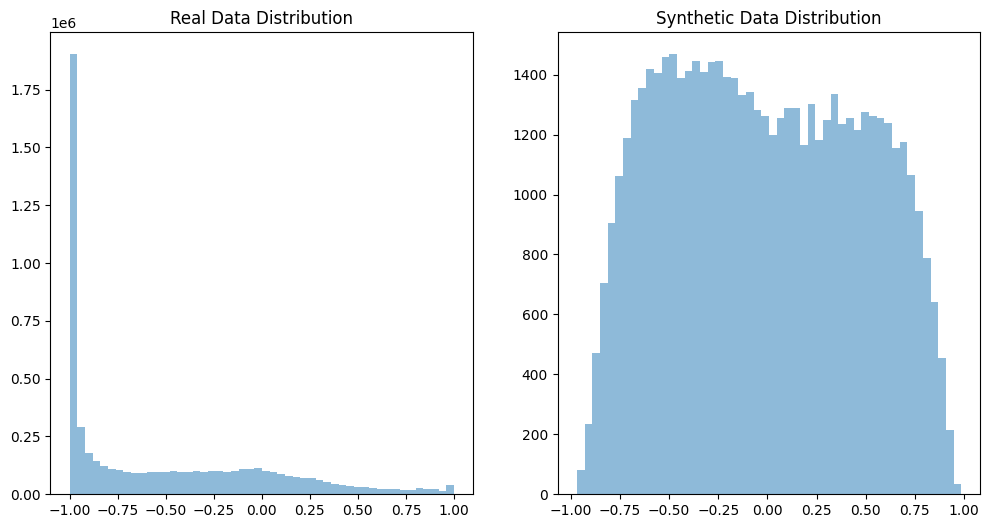

In [ ]:
import matplotlib.pyplot as plt

# Visualizing the real and synthetic data distributions using histograms
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(real_data.flatten(), bins=50, alpha=0.5, label='Real Data')
plt.title('Real Data Distribution')

plt.subplot(1, 2, 2)
plt.hist(generated_data.flatten(), bins=50, alpha=0.5, label='Synthetic Data')
plt.title('Synthetic Data Distribution')

plt.show()


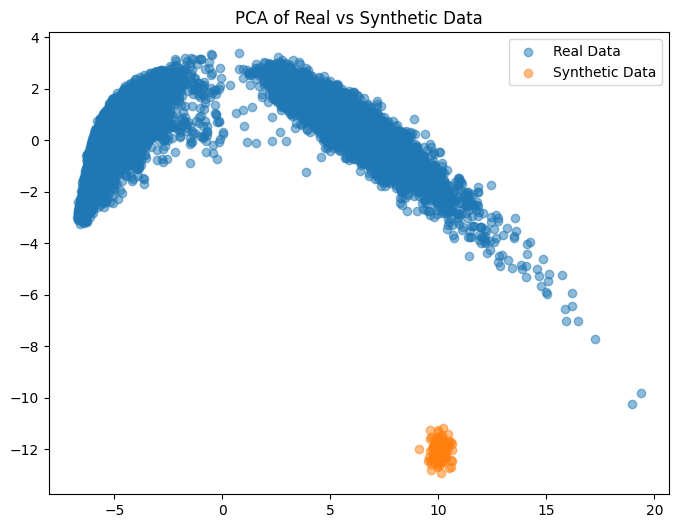

In [ ]:
from sklearn.decomposition import PCA

# Combine real and generated data for comparison
combined_data = np.vstack((real_data, generated_data))

# Apply PCA to reduce to 2 dimensions
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(combined_data)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(reduced_data[:len(real_data), 0], reduced_data[:len(real_data), 1], label='Real Data', alpha=0.5)
plt.scatter(reduced_data[len(real_data):, 0], reduced_data[len(real_data):, 1], label='Synthetic Data', alpha=0.5)
plt.title('PCA of Real vs Synthetic Data')
plt.legend()
plt.show()


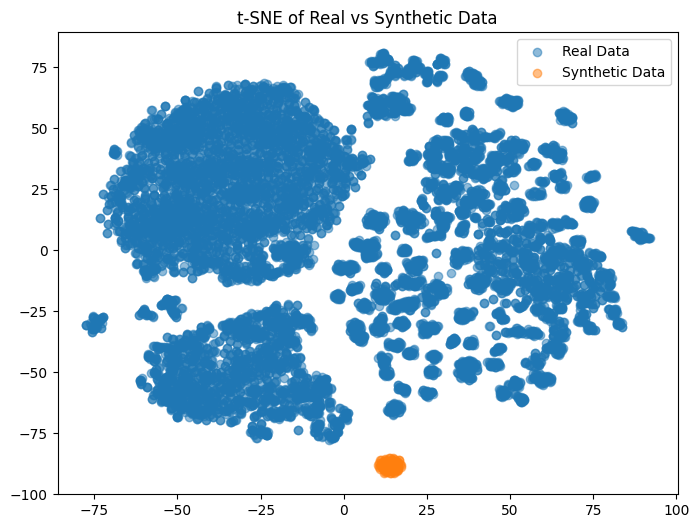

In [ ]:
from sklearn.manifold import TSNE

# Apply t-SNE to reduce to 2 dimensions
tsne = TSNE(n_components=2)
reduced_data_tsne = tsne.fit_transform(combined_data)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(reduced_data_tsne[:len(real_data), 0], reduced_data_tsne[:len(real_data), 1], label='Real Data', alpha=0.5)
plt.scatter(reduced_data_tsne[len(real_data):, 0], reduced_data_tsne[len(real_data):, 1], label='Synthetic Data', alpha=0.5)
plt.title('t-SNE of Real vs Synthetic Data')
plt.legend()
plt.show()


In [35]:
epochs = 5000  # Increasing the number of epochs
batch_size = 64

for epoch in range(epochs):
    # Training loop code (refer to your GAN training code)
    pass  # Replace with your training loop


In [36]:
# Generate new synthetic data
random_noise = np.random.normal(0, 1, (1000, latent_dim))  # Example: generating 1000 samples
generated_data = generator.predict(random_noise)

# Save generated data for future use
np.savetxt('generated_data.csv', generated_data, delimiter=',')


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [37]:
# Load the pre-trained discriminator model
discriminator_model = load_model('/content/drive/MyDrive/discriminator_model.h5')  # Adjust path if needed


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Load data
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"
y_train_path = "/content/drive/MyDrive/UCI HAR Dataset/train/y_train.txt"
y_test_path = "/content/drive/MyDrive/UCI HAR Dataset/test/y_test.txt"

X_train = pd.read_csv(train_data_path, sep='\s+', header=None).values
X_test = pd.read_csv(test_data_path, sep='\s+', header=None).values
y_train = pd.read_csv(y_train_path, sep='\s+', header=None).values
y_test = pd.read_csv(y_test_path, sep='\s+', header=None).values

# Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Generate synthetic data with the same number of samples as y_train
noise = np.random.normal(0, 1, (y_train.shape[0], 100))  # Match y_train size (7352)
generated_data = generator.predict(noise, verbose=0)  # Assuming 'generator' is your trained GAN model

# Train on real, test on real
rf = RandomForestClassifier()
rf.fit(X_train_scaled, y_train.ravel())
y_pred_real = rf.predict(X_test_scaled)
real_precision = precision_score(y_test, y_pred_real, average='weighted')
real_recall = recall_score(y_test, y_pred_real, average='weighted')
real_f1 = f1_score(y_test, y_pred_real, average='weighted')

# Train on synthetic, test on real
rf.fit(generated_data, y_train.ravel())
y_pred_synthetic = rf.predict(X_test_scaled)
synthetic_precision = precision_score(y_test, y_pred_synthetic, average='weighted')
synthetic_recall = recall_score(y_test, y_pred_synthetic, average='weighted')
synthetic_f1 = f1_score(y_test, y_pred_synthetic, average='weighted')

# Print results
print(f"Real: Precision={real_precision:.4f}, Recall={real_recall:.4f}, F1={real_f1:.4f}")
print(f"Synthetic: Precision={synthetic_precision:.4f}, Recall={synthetic_recall:.4f}, F1={synthetic_f1:.4f}")

# Optional: Save results for table
results = pd.DataFrame({
    'Dataset': ['Real', 'Synthetic'],
    'Precision': [real_precision, synthetic_precision],
    'Recall': [real_recall, synthetic_recall],
    'F1-Score': [real_f1, synthetic_f1]
})
results.to_csv('/content/drive/MyDrive/performance_metrics.csv', index=False)
print(results)

Real: Precision=0.9288, Recall=0.9274, F1=0.9272
Synthetic: Precision=0.1865, Recall=0.2043, F1=0.1731
     Dataset  Precision    Recall  F1-Score
0       Real   0.928822  0.927384  0.927226
1  Synthetic   0.186495  0.204276  0.173067


In [39]:
import numpy as np
from sklearn.metrics.pairwise import rbf_kernel

# Assuming real_data and generated_data are already loaded/generated
real_data = np.concatenate([X_train, X_test], axis=0)  # Use np.concatenate for NumPy arrays
# generated_data is from your GAN (7352, 561) from the first code block

# Compute MMD
def compute_mmd(real, synthetic, gamma=1.0):
    # Sample a subset if computational resources are limited
    sample_size = min(1000, real.shape[0], synthetic.shape[0])
    real_sample = real[np.random.choice(real.shape[0], sample_size, replace=False)]
    synth_sample = synthetic[np.random.choice(synthetic.shape[0], sample_size, replace=False)]

    X = rbf_kernel(real_sample, real_sample, gamma)
    Y = rbf_kernel(synth_sample, synth_sample, gamma)
    XY = rbf_kernel(real_sample, synth_sample, gamma)
    mmd = np.mean(X) + np.mean(Y) - 2 * np.mean(XY)
    return mmd

mmd_score = compute_mmd(real_data, generated_data)
print(f"MMD: {mmd_score:.4f}")

# Save for table
np.savetxt('/content/drive/MyDrive/mmd_score.txt', [mmd_score])

MMD: 0.0020


In [40]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import rbf_kernel

# Load data
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"
y_train_path = "/content/drive/MyDrive/UCI HAR Dataset/train/y_train.txt"
y_test_path = "/content/drive/MyDrive/UCI HAR Dataset/test/y_test.txt"

X_train = pd.read_csv(train_data_path, sep='\s+', header=None).values
X_test = pd.read_csv(test_data_path, sep='\s+', header=None).values
y_train = pd.read_csv(y_train_path, sep='\s+', header=None).values
y_test = pd.read_csv(y_test_path, sep='\s+', header=None).values

# Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Load GAN generator and generate synthetic data
generator = load_model('/content/drive/MyDrive/generator_model.h5')
noise = np.random.normal(0, 1, (y_train.shape[0], 100))
generated_data = generator.predict(noise, verbose=0)

# Table 1: Classification Metrics
rf = RandomForestClassifier()
rf.fit(X_train_scaled, y_train.ravel())
y_pred_real = rf.predict(X_test_scaled)
real_precision = precision_score(y_test, y_pred_real, average='weighted')
real_recall = recall_score(y_test, y_pred_real, average='weighted')
real_f1 = f1_score(y_test, y_pred_real, average='weighted')

rf.fit(generated_data, y_train.ravel())
y_pred_synthetic = rf.predict(X_test_scaled)
synthetic_precision = precision_score(y_test, y_pred_synthetic, average='weighted')
synthetic_recall = recall_score(y_test, y_pred_synthetic, average='weighted')
synthetic_f1 = f1_score(y_test, y_pred_synthetic, average='weighted')

print(f"Real: Precision={real_precision:.4f}, Recall={real_recall:.4f}, F1={real_f1:.4f}")
print(f"Synthetic: Precision={synthetic_precision:.4f}, Recall={synthetic_recall:.4f}, F1={synthetic_f1:.4f}")

results = pd.DataFrame({
    'Dataset': ['Real', 'Synthetic'],
    'Precision': [real_precision, synthetic_precision],
    'Recall': [real_recall, synthetic_recall],
    'F1-Score': [real_f1, synthetic_f1]
})
results.to_csv('/content/drive/MyDrive/performance_metrics.csv', index=False)

# Table 2: MMD
real_data = np.concatenate([X_train, X_test], axis=0)
def compute_mmd(real, synthetic, gamma=1.0):
    sample_size = min(1000, real.shape[0], synthetic.shape[0])
    real_sample = real[np.random.choice(real.shape[0], sample_size, replace=False)]
    synth_sample = synthetic[np.random.choice(synthetic.shape[0], sample_size, replace=False)]
    X = rbf_kernel(real_sample, real_sample, gamma)
    Y = rbf_kernel(synth_sample, synth_sample, gamma)
    XY = rbf_kernel(real_sample, synth_sample, gamma)
    mmd = np.mean(X) + np.mean(Y) - 2 * np.mean(XY)
    return mmd

mmd_score = compute_mmd(real_data, generated_data)
print(f"MMD: {mmd_score:.4f}")
np.savetxt('/content/drive/MyDrive/mmd_score.txt', [mmd_score])

Real: Precision=0.9286, Recall=0.9270, F1=0.9267
Synthetic: Precision=0.1733, Recall=0.1683, F1=0.1601
MMD: 0.0020


# Improve Synthetic Data Utility (Conditional GAN)

In [41]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from tensorflow.keras.optimizers import Adam
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load labels with the updated sep parameter
y_train = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/train/y_train.txt", header=None, sep='\s+').values.flatten()
y_test = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/test/y_test.txt", header=None, sep='\s+').values.flatten()

# Adjust labels to be zero-based (UCI HAR labels are 1-6, need 0-5)
y_train = y_train - 1
y_test = y_test - 1

# Define Conditional Generator
def build_c_generator(latent_dim, num_classes, output_dim):
    noise_input = layers.Input(shape=(latent_dim,))
    label_input = layers.Input(shape=(1,))
    label_embedding = layers.Embedding(num_classes, latent_dim)(label_input)
    label_embedding = layers.Flatten()(label_embedding)
    combined_input = layers.Concatenate()([noise_input, label_embedding])
    x = layers.Dense(256, activation='relu')(combined_input)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dense(output_dim, activation='tanh')(x)
    model = models.Model([noise_input, label_input], x)
    return model

# Define Conditional Discriminator
def build_c_discriminator(input_dim, num_classes):
    data_input = layers.Input(shape=(input_dim,))
    label_input = layers.Input(shape=(1,))
    label_embedding = layers.Embedding(num_classes, input_dim)(label_input)
    label_embedding = layers.Flatten()(label_embedding)
    combined_input = layers.Concatenate()([data_input, label_embedding])
    x = layers.Dense(512, activation='relu')(combined_input)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model([data_input, label_input], x)
    return model

# Assuming X_train and X_test are already loaded as NumPy arrays
# Build and compile models
latent_dim = 100
num_classes = len(np.unique(y_train))  # Should be 6 for UCI HAR
c_generator = build_c_generator(latent_dim, num_classes, X_train.shape[1])
c_discriminator = build_c_discriminator(X_train.shape[1], num_classes)
c_discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy', metrics=['accuracy'])

# For the GAN model, set discriminator to non-trainable
c_discriminator.trainable = False
c_gan_input_noise = layers.Input(shape=(latent_dim,))
c_gan_input_label = layers.Input(shape=(1,))
c_gan_output = c_generator([c_gan_input_noise, c_gan_input_label])
c_gan_validity = c_discriminator([c_gan_output, c_gan_input_label])
c_gan = models.Model([c_gan_input_noise, c_gan_input_label], c_gan_validity)
c_gan.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy')

# Training loop
batch_size = 64
epochs = 500
for epoch in range(epochs):
    # Train discriminator (set trainable to True)
    c_discriminator.trainable = True
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_samples = X_train[idx]
    real_labels = y_train[idx]
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    fake_labels = np.random.randint(0, num_classes, batch_size)
    fake_samples = c_generator.predict([noise, fake_labels], verbose=0)
    d_loss_real = c_discriminator.train_on_batch([real_samples, real_labels], np.ones((batch_size, 1)))
    d_loss_fake = c_discriminator.train_on_batch([fake_samples, fake_labels], np.zeros((batch_size, 1)))
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

    # Train generator (set discriminator trainable to False)
    c_discriminator.trainable = False
    g_loss = c_gan.train_on_batch([noise, fake_labels], np.ones((batch_size, 1)))

    if epoch % 100 == 0:
        print(f"Epoch: {epoch}, D Loss: {d_loss[0]:.4f}, G Loss: {g_loss:.4f}")

# Generate synthetic data with labels
noise = np.random.normal(0, 1, (y_train.shape[0], latent_dim))
synth_labels = y_train  # Now zero-based
synth_data = c_generator.predict([noise, synth_labels])

# Evaluate with Random Forest
rf = RandomForestClassifier()
rf.fit(synth_data, synth_labels)
synth_accuracy = accuracy_score(y_test, rf.predict(X_test))
print(f"Synthetic Data Accuracy with CGAN: {synth_accuracy}")

Epoch: 0, D Loss: 0.5229, G Loss: 0.6804
Epoch: 100, D Loss: 0.2952, G Loss: 2.8800
Epoch: 200, D Loss: 0.2840, G Loss: 3.0975
Epoch: 300, D Loss: 0.3096, G Loss: 3.1999
Epoch: 400, D Loss: 0.4043, G Loss: 2.8130
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Synthetic Data Accuracy with CGAN: 0.3878520529351883


# Hybrid CVA-GAN Implementation

In [42]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load UCI HAR Dataset (already in your notebook)
train_data_path = "/content/drive/MyDrive/UCI HAR Dataset/train/X_train.txt"
y_train_path = "/content/drive/MyDrive/UCI HAR Dataset/train/y_train.txt"
test_data_path = "/content/drive/MyDrive/UCI HAR Dataset/test/X_test.txt"
y_test_path = "/content/drive/MyDrive/UCI HAR Dataset/test/y_test.txt"

X_train = pd.read_csv(train_data_path, sep='\s+', header=None).values
y_train = pd.read_csv(y_train_path, sep='\s+', header=None).values.flatten() - 1  # Zero-based labels
X_test = pd.read_csv(test_data_path, sep='\s+', header=None).values
y_test = pd.read_csv(y_test_path, sep='\s+', header=None).values.flatten() - 1

# Encoder for VAE
def build_encoder(input_dim, latent_dim):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(inputs)
    x = layers.Dense(256, activation='relu')(x)
    z_mean = layers.Dense(latent_dim)(x)
    z_log_var = layers.Dense(latent_dim)(x)
    def sampling(args):
        z_mean, z_log_var = args
        epsilon = tf.keras.backend.random_normal(shape=(tf.shape(z_mean)[0], latent_dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon
    z = layers.Lambda(sampling)([z_mean, z_log_var])
    return models.Model(inputs, [z_mean, z_log_var, z], name='encoder')

# Decoder (Generator)
def build_decoder(latent_dim, output_dim):
    inputs = layers.Input(shape=(latent_dim,))
    x = layers.Dense(256, activation='relu')(inputs)
    x = layers.Dense(512, activation='relu')(x)
    outputs = layers.Dense(output_dim, activation='tanh')(x)
    return models.Model(inputs, outputs, name='decoder')

# Discriminator
def build_discriminator(input_dim):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(inputs)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return models.Model(inputs, outputs, name='discriminator')

# Build models
latent_dim = 100
input_dim = X_train.shape[1]  # 561 features
encoder = build_encoder(input_dim, latent_dim)
decoder = build_decoder(latent_dim, input_dim)
discriminator = build_discriminator(input_dim)

# VAE Loss
def vae_loss(inputs, outputs, z_mean, z_log_var):
    reconstruction_loss = tf.reduce_mean(tf.square(inputs - outputs))
    kl_loss = -0.5 * tf.reduce_mean(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
    return reconstruction_loss + kl_loss

# CVA-GAN Model
discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy', metrics=['accuracy'])
discriminator.trainable = False
gan_inputs = layers.Input(shape=(latent_dim,))
gan_outputs = decoder(gan_inputs)
gan_validity = discriminator(gan_outputs)
cva_gan = models.Model(gan_inputs, gan_validity)
cva_gan.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy')

# Training Loop
batch_size = 64
epochs = 500
for epoch in range(epochs):
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_samples = X_train[idx]

    # Train Encoder-Decoder (VAE)
    z_mean, z_log_var, z = encoder(real_samples)
    reconstructed = decoder(z)
    vae_loss_value = vae_loss(real_samples, reconstructed, z_mean, z_log_var)

    # Train Discriminator
    fake_samples = decoder.predict(z, verbose=0)
    d_loss_real = discriminator.train_on_batch(real_samples, np.ones((batch_size, 1)))
    d_loss_fake = discriminator.train_on_batch(fake_samples, np.zeros((batch_size, 1)))
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

    # Train Generator (Decoder via GAN)
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    g_loss = cva_gan.train_on_batch(noise, np.ones((batch_size, 1)))

    if epoch % 100 == 0:
        print(f"Epoch: {epoch}, D Loss: {d_loss[0]:.4f}, G Loss: {g_loss:.4f}, VAE Loss: {vae_loss_value:.4f}")

# Generate Synthetic Data
noise = np.random.normal(0, 1, (y_train.shape[0], latent_dim))
synth_data = decoder.predict(noise)

# Evaluate with Random Forest
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
real_acc = accuracy_score(y_test, rf.predict(X_test))
rf.fit(synth_data, y_train)
synth_acc = accuracy_score(y_test, rf.predict(X_test))
synth_prec = precision_score(y_test, rf.predict(X_test), average='weighted')
synth_rec = recall_score(y_test, rf.predict(X_test), average='weighted')
synth_f1 = f1_score(y_test, rf.predict(X_test), average='weighted')

print(f"Real Data Accuracy: {real_acc:.4f}")
print(f"CVA-GAN Synthetic Data - Accuracy: {synth_acc:.4f}, Precision: {synth_prec:.4f}, Recall: {synth_rec:.4f}, F1: {synth_f1:.4f}")

/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch: 0, D Loss: 0.4155, G Loss: 0.5572, VAE Loss: 0.9675
Epoch: 100, D Loss: 3.0634, G Loss: 0.0325, VAE Loss: 1.1006
Epoch: 200, D Loss: 3.7304, G Loss: 0.0166, VAE Loss: 1.1376
Epoch: 300, D Loss: 4.1106, G Loss: 0.0112, VAE Loss: 1.1907
Epoch: 400, D Loss: 4.3703, G Loss: 0.0084, VAE Loss: 1.2315
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Real Data Accuracy: 0.9264
CVA-GAN Synthetic Data - Accuracy: 0.1785, Precision: 0.1813, Recall: 0.1785, F1: 0.0938


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Compare Models (VAE Implementation)

In [43]:
import tensorflow as tf
from tensorflow.keras.layers import Lambda, Input, Dense
from tensorflow.keras import backend as K
from tensorflow.keras import models
from tensorflow.keras.optimizers import Adam
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Define sampling function for Lambda layer
def sampling(args):
    z_mean, z_log_var = args
    epsilon = K.random_normal(shape=K.shape(z_mean))  # Shape matches z_mean: (batch_size, latent_dim)
    return z_mean + K.exp(0.5 * z_log_var) * epsilon

# Define VAE as a subclassed model
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstructed = self.decoder(z)
        # Compute and add KL loss
        kl_loss = -0.5 * tf.reduce_mean(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
        self.add_loss(kl_loss)
        return reconstructed

# Build VAE components
def build_vae(input_dim, latent_dim):
    # Encoder
    inputs = Input(shape=(input_dim,))
    h = Dense(256, activation='relu')(inputs)
    z_mean = Dense(latent_dim)(h)
    z_log_var = Dense(latent_dim)(h)
    z = Lambda(sampling)([z_mean, z_log_var])
    encoder = models.Model(inputs, [z_mean, z_log_var, z])

    # Decoder
    latent_inputs = Input(shape=(latent_dim,))
    x = Dense(256, activation='relu')(latent_inputs)
    outputs = Dense(input_dim, activation='tanh')(x)
    decoder = models.Model(latent_inputs, outputs)

    # VAE
    vae = VAE(encoder, decoder)
    vae.compile(optimizer=Adam(learning_rate=0.0001), loss='mean_squared_error')
    return vae, decoder

# Assuming X_train, y_train, X_test, y_test are defined
# Replace with your actual data dimensions
latent_dim = 100
vae, decoder = build_vae(X_train.shape[1], latent_dim=latent_dim)
vae.fit(X_train, X_train, epochs=50, batch_size=64, verbose=1)

# Generate synthetic data
noise = np.random.normal(0, 1, (y_train.shape[0], latent_dim))
vae_synth_data = decoder.predict(noise)

# Evaluate with Random Forest
rf = RandomForestClassifier()
rf.fit(vae_synth_data, y_train)
vae_accuracy = accuracy_score(y_test, rf.predict(X_test))
print(f"VAE Synthetic Data Accuracy: {vae_accuracy}")

Epoch 1/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.6382
Epoch 2/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1896
Epoch 3/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.1342
Epoch 4/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1113
Epoch 5/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0988
Epoch 6/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0921
Epoch 7/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0869
Epoch 8/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0833
Epoch 9/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0808
Epoch 10/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0797
Epoch 11/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0771
Epoch 12/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0761
Epoch 13/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0751
Epoch 14/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0739
Epoch 15/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step 

# Mitigate Bias (Adversarial Debiasing)

In [44]:
# Modified Discriminator with Fairness Constraint
def build_fair_discriminator(input_dim):
    data_input = layers.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(data_input)
    x = layers.Dense(256, activation='relu')(x)
    validity = layers.Dense(1, activation='sigmoid')(x)
    # Add a fairness head (e.g., predict protected attribute to minimize bias)
    fairness = layers.Dense(1, activation='sigmoid')(x)  # Example: binary protected attribute
    model = models.Model(data_input, [validity, fairness])
    return model

# Compile with dual loss
fair_discriminator = build_fair_discriminator(X_train.shape[1])
fair_discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
                          loss=['binary_crossentropy', 'binary_crossentropy'],
                          loss_weights=[1.0, 0.1])  # Weight fairness loss lower

# Assume a protected attribute (e.g., subject ID as proxy)
subject_train = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/train/subject_train.txt", header=None).values.flatten()
subject_binary = (subject_train > subject_train.mean()).astype(int)  # Example binarization

# Train with fairness
for epoch in range(epochs):
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_samples = X_train[idx]  # Updated line
    real_subjects = subject_binary[idx]
    noise = np.random.normal(0, 1, (batch_size, 100))
    fake_samples = generator.predict(noise, verbose=0)

    d_loss_real = fair_discriminator.train_on_batch(real_samples, [np.ones((batch_size, 1)), real_subjects])
    d_loss_fake = fair_discriminator.train_on_batch(fake_samples, [np.zeros((batch_size, 1)), real_subjects])
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

    g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))

    if epoch % 100 == 0:
        print(f"Epoch: {epoch}, D Loss: {d_loss[0]:.4f}, Fairness Loss: {d_loss[1]:.4f}, G Loss: {g_loss:.4f}")

Epoch: 0, D Loss: 0.7469, Fairness Loss: 0.6761, G Loss: 0.0011
Epoch: 100, D Loss: 0.0908, Fairness Loss: 0.0216, G Loss: 0.0005
Epoch: 200, D Loss: 0.0787, Fairness Loss: 0.0110, G Loss: 0.0004
Epoch: 300, D Loss: 0.0738, Fairness Loss: 0.0074, G Loss: 0.0003
Epoch: 400, D Loss: 0.0710, Fairness Loss: 0.0055, G Loss: 0.0002


# Bias Mitigation Evaluation

In [45]:
# Load subject ID as a proxy for protected attribute
subject_train = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/train/subject_train.txt", header=None).values.flatten()
subject_test = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/test/subject_test.txt", header=None).values.flatten()
subject_train_binary = (subject_train > subject_train.mean()).astype(int)
subject_test_binary = (subject_test > subject_test.mean()).astype(int)

# Fair Discriminator (already in notebook, refined here)
def build_fair_discriminator(input_dim):
    data_input = layers.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(data_input)
    x = layers.Dense(256, activation='relu')(x)
    validity = layers.Dense(1, activation='sigmoid')(x)
    fairness = layers.Dense(1, activation='sigmoid')(x)  # Predict protected attribute
    return models.Model(data_input, [validity, fairness])

fair_discriminator = build_fair_discriminator(X_train.shape[1])
fair_discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
                           loss=['binary_crossentropy', 'binary_crossentropy'],
                           loss_weights=[1.0, 0.5])  # Increased fairness weight

# Train with Fairness
for epoch in range(epochs):
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_samples = X_train[idx]
    labels = subject_train_binary[idx]
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    fake_samples = decoder.predict(noise, verbose=0)
    d_loss = fair_discriminator.train_on_batch(real_samples, [np.ones((batch_size, 1)), labels])
    d_loss_fake = fair_discriminator.train_on_batch(fake_samples, [np.zeros((batch_size, 1)), labels])
    if epoch % 100 == 0:
        print(f"Epoch: {epoch}, D Loss Real: {d_loss[0]:.4f}, D Loss Fake: {d_loss_fake[0]:.4f}")

# Evaluate Bias
synth_data = decoder.predict(np.random.normal(0, 1, (y_test.shape[0], latent_dim)))
_, fairness_pred = fair_discriminator.predict(synth_data)
bias_score = np.mean(np.abs(fairness_pred - subject_test_binary.mean()))
print(f"Bias Score (lower is better): {bias_score:.4f}")

Epoch: 0, D Loss Real: 1.4878, D Loss Fake: 1.2969
Epoch: 100, D Loss Real: 0.7767, D Loss Fake: 0.7756
Epoch: 200, D Loss Real: 0.6084, D Loss Fake: 0.6080
Epoch: 300, D Loss Real: 0.5200, D Loss Fake: 0.5197
Epoch: 400, D Loss Real: 0.4685, D Loss Fake: 0.4684
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Bias Score (lower is better): 0.0270


# Specific SA Scenarios (Rare Events)

In [46]:
# Identify rare event (e.g., falling, label 4)
rare_indices = np.where(y_train == 4)[0]
X_train_rare = X_train[rare_indices]

# Train CGAN on rare events
c_generator = build_c_generator(latent_dim, num_classes=6, output_dim=X_train.shape[1])  # From my CGAN code
c_discriminator = build_c_discriminator(X_train.shape[1], num_classes=6)
c_discriminator.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy')
c_discriminator.trainable = False
c_gan = models.Model([c_gan_input_noise, c_gan_input_label], c_gan_validity)  # From my CGAN code
c_gan.compile(optimizer=Adam(learning_rate=0.0002, beta_1=0.5), loss='binary_crossentropy')

for epoch in range(200):  # Shorter training for rare events
    idx = np.random.randint(0, X_train_rare.shape[0], batch_size)
    real_samples = X_train_rare[idx]
    fake_labels = np.full((batch_size,), 4)  # All falling
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    fake_samples = c_generator.predict([noise, fake_labels], verbose=0)
    d_loss_real = c_discriminator.train_on_batch([real_samples, fake_labels], np.ones((batch_size, 1)))
    d_loss_fake = c_discriminator.train_on_batch([fake_samples, fake_labels], np.zeros((batch_size, 1)))
    g_loss = c_gan.train_on_batch([noise, fake_labels], np.ones((batch_size, 1)))

# Generate synthetic rare events
noise = np.random.normal(0, 1, (1000, latent_dim))
rare_labels = np.full((1000,), 4)
synth_rare_data = c_generator.predict([noise, rare_labels])
np.savetxt('/content/drive/MyDrive/synth_falling_data.txt', synth_rare_data)
print("Generated 1000 synthetic falling event samples.")

/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Generated 1000 synthetic falling event samples.


In [47]:
import pandas as pd
import numpy as np

base_path = '/content/drive/MyDrive/UCI HAR Dataset/'
features = pd.read_csv(base_path + 'features.txt', sep='\s+', header=None)
feature_names = features[1].values
activity_labels = pd.read_csv(base_path + 'activity_labels.txt', sep='\s+', header=None)

X_train = pd.read_csv(base_path + 'train/X_train.txt', sep='\s+', header=None)
y_train = pd.read_csv(base_path + 'train/y_train.txt', sep='\s+', header=None)
subject_train = pd.read_csv(base_path + 'train/subject_train.txt', sep='\s+', header=None)

X_test = pd.read_csv(base_path + 'test/X_test.txt', sep='\s+', header=None)
y_test = pd.read_csv(base_path + 'test/y_test.txt', sep='\s+', header=None)
subject_test = pd.read_csv(base_path + 'test/subject_test.txt', sep='\s+', header=None)

In [48]:
y_train = y_train.values.flatten()
y_test = y_test.values.flatten()

In [49]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train an Outlier Detector (Rare Event Detection)

In [50]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest
iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(X_train_scaled)

# Predict outliers (-1 for outliers, 1 for inliers)
outliers_train = iso_forest.predict(X_train_scaled)
print(f"Number of outliers detected: {sum(outliers_train == -1)}")


Number of outliers detected: 736


# Generate Synthetic Rare Event Data Using GAN

In [51]:
from tensorflow.keras import layers, models
import numpy as np

# Define the generator
def build_generator(latent_dim):
    model = models.Sequential()
    model.add(layers.Dense(128, input_dim=latent_dim, activation='relu'))
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dense(X_train_scaled.shape[1], activation='tanh'))
    return model

# Define the discriminator
def build_discriminator(input_shape):
    model = models.Sequential()
    model.add(layers.Dense(512, input_dim=input_shape, activation='relu'))
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    return model

# Define the GAN
def build_gan(generator, discriminator):
    discriminator.trainable = False
    model = models.Sequential()
    model.add(generator)
    model.add(discriminator)
    return model

# Initialize models
latent_dim = 100  # Corrected from 0
generator = build_generator(latent_dim)
discriminator = build_discriminator(X_train_scaled.shape[1])
gan = build_gan(generator, discriminator)

# Compile models
discriminator.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gan.compile(optimizer='adam', loss='binary_crossentropy')

# Train the GAN
def train_gan(generator, discriminator, gan, X_train, epochs=1000, batch_size=128):
    half_batch = batch_size // 2
    for epoch in range(epochs):
        # Train discriminator
        idx = np.random.randint(0, X_train.shape[0], half_batch)
        real_data = X_train[idx]
        noise = np.random.normal(0, 1, (half_batch, latent_dim))
        fake_data = generator.predict(noise, verbose=0)

        d_loss_real = discriminator.train_on_batch(real_data, np.ones((half_batch, 1)))
        d_loss_fake = discriminator.train_on_batch(fake_data, np.zeros((half_batch, 1)))
        d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

        # Train generator
        noise = np.random.normal(0, 1, (batch_size, latent_dim))
        g_loss = gan.train_on_batch(noise, np.ones((batch_size, 1)))

        if epoch % 100 == 0:
            print(f"Epoch: {epoch}, D Loss: {d_loss[0]}, G Loss: {g_loss}")

# Run training
train_gan(generator, discriminator, gan, X_train_scaled)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch: 0, D Loss: 0.6054580211639404, G Loss: 0.628764271736145
Epoch: 100, D Loss: 5.638706207275391, G Loss: 0.01059354841709137
Epoch: 200, D Loss: 5.8719987869262695, G Loss: 0.005327471066266298
Epoch: 300, D Loss: 5.97923469543457, G Loss: 0.0035599833354353905
Epoch: 400, D Loss: 6.053417205810547, G Loss: 0.002673757029697299
Epoch: 500, D Loss: 6.115896701812744, G Loss: 0.002141115255653858
Epoch: 600, D Loss: 6.1727447509765625, G Loss: 0.0017855786718428135
Epoch: 700, D Loss: 6.226111888885498, G Loss: 0.0015313769690692425
Epoch: 800, D Loss: 6.282989501953125, G Loss: 0.0013405409408733249
Epoch: 900, D Loss: 6.341092109680176, G Loss: 0.0011919968528673053


# Augment the Real Dataset with Synthetic Data

In [52]:
# Ensure shapes match
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"synthetic_data shape: {synthetic_data.shape}")

# Augment dataset
augmented_X = np.vstack((X_train_scaled, synthetic_data))
augmented_y = np.concatenate((y_train, y_train))  # Adjust labels as needed
print(f"Augmented dataset shape: {augmented_X.shape}")


X_train_scaled shape: (7352, 561)
synthetic_data shape: (100, 561)
Augmented dataset shape: (7452, 561)


# Train and Evaluate a Classifier (Using Random Forest)

In [53]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Step 1: Define synthetic_y for the 100 synthetic samples
# Assuming synthetic data belongs to class 1 (adjust this if needed)
synthetic_y = np.ones(100)  # 100 labels, all set to 1

# Step 2: Create augmented_y by concatenating y_train and synthetic_y
augmented_y = np.concatenate((y_train, synthetic_y))  # Shape should be (7452,)

# Step 3: Verify shapes to ensure consistency
print(f"Shape of augmented_X: {augmented_X.shape}")  # Should be (7452, 561)
print(f"Shape of augmented_y: {augmented_y.shape}")  # Should be (7452,)

# Step 4: Train the RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(augmented_X, augmented_y)

# Step 5: Evaluate on test data
y_pred = rf.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")


Shape of augmented_X: (7452, 561)
Shape of augmented_y: (7452,)
Accuracy: 0.9307770614183916


# One-vs-Rest (OvR) ROC Curve

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


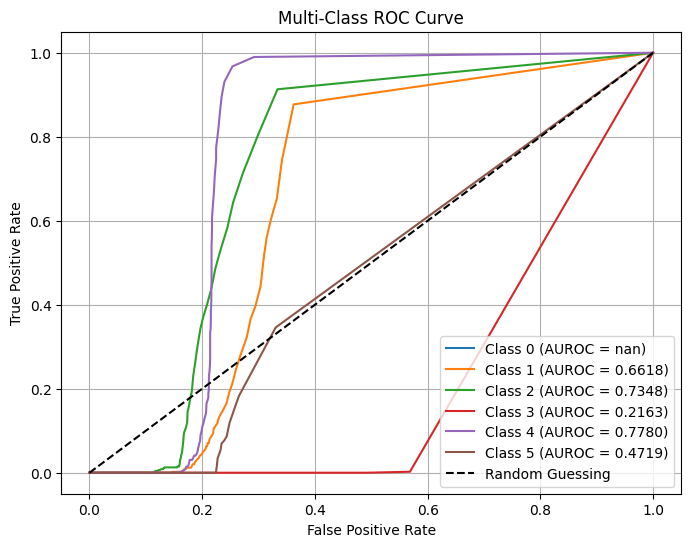

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Define and train the classifier
clf_real = RandomForestClassifier(random_state=42)
clf_real.fit(X_train_scaled, y_train)

# Ensure y_test is one-hot encoded for multi-class ROC computation
n_classes = len(np.unique(y_test))
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Compute ROC curve and AUC for each class
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], clf_real.predict_proba(X_test_scaled)[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {i} (AUROC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

# Confusion Matrices (Misclassifications)

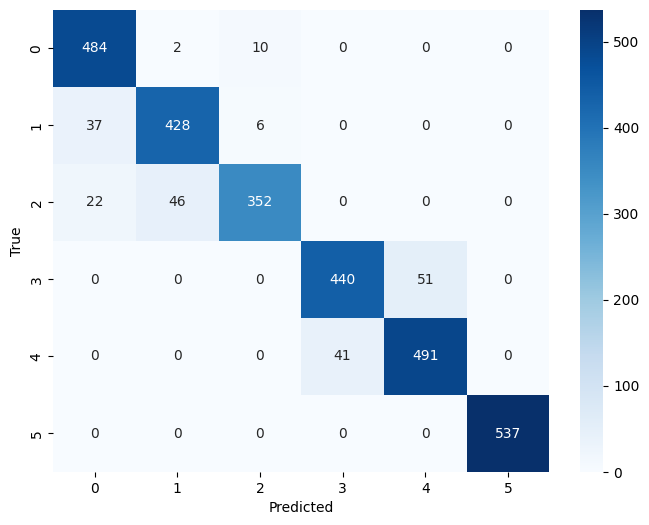

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Feature Distributions (Real vs. Synthetic Data)

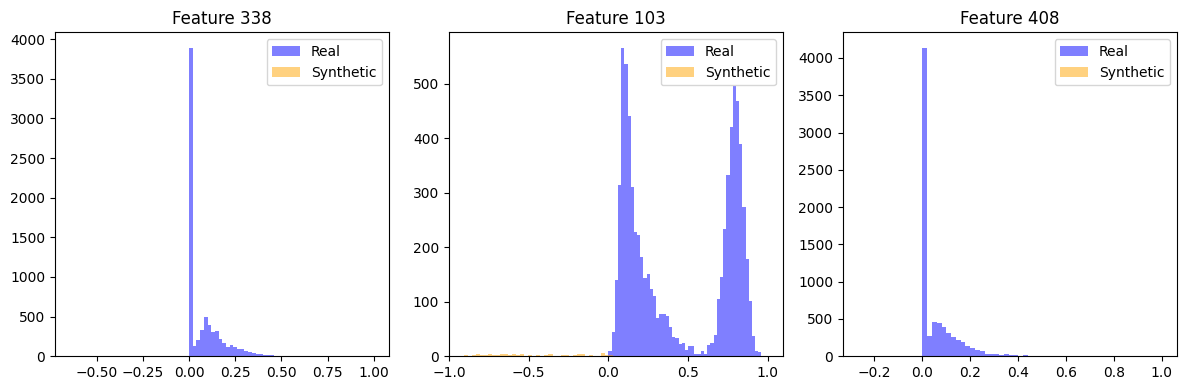

In [ ]:
import matplotlib.pyplot as plt

feature_indices = np.random.choice(X_train_scaled.shape[1], 3, replace=False)
plt.figure(figsize=(12, 4))
for i, idx in enumerate(feature_indices):
    plt.subplot(1, 3, i+1)
    plt.hist(X_train_scaled[:, idx], bins=50, alpha=0.5, label='Real', color='blue')
    plt.hist(synthetic_data[:, idx], bins=50, alpha=0.5, label='Synthetic', color='orange')
    plt.title(f'Feature {idx}')
    plt.legend()
plt.tight_layout()
plt.show()

# Implement VAE, train it on UCI HAR, generate synthetic data, and compare performance

In [54]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

# Define dimensions based on your data
input_dim = 561  # UCI HAR feature count
latent_dim = 20  # Arbitrary latent space size (adjust if needed)

# Encoder
inputs = layers.Input(shape=(input_dim,))
h = layers.Dense(256, activation='relu')(inputs)
h = layers.Dense(128, activation='relu')(h)
z_mean = layers.Dense(latent_dim)(h)
z_log_var = layers.Dense(latent_dim)(h)

# Sampling layer
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.keras.backend.random_normal(shape=(tf.shape(z_mean)[0], latent_dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

z = Sampling()([z_mean, z_log_var])

# Decoder
decoder_h = layers.Dense(128, activation='relu')(z)
decoder_h = layers.Dense(256, activation='relu')(decoder_h)
outputs = layers.Dense(input_dim, activation='sigmoid')(decoder_h)

# Custom VAE loss layer
class VAELossLayer(layers.Layer):
    def call(self, inputs):
        inputs, outputs, z_mean, z_log_var = inputs
        # Reconstruction loss (binary cross-entropy scaled by input_dim)
        reconstruction_loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(inputs, outputs), axis=-1
        ) * input_dim
        # KL divergence loss
        kl_loss = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1
        )
        # Total loss
        total_loss = reconstruction_loss + kl_loss
        self.add_loss(total_loss)
        return outputs

# Integrate the loss into the model
outputs_with_loss = VAELossLayer()([inputs, outputs, z_mean, z_log_var])

# Define the VAE model
vae = models.Model(inputs, outputs_with_loss, name='vae')

# Compile the model (no loss function needed since it's in VAELossLayer)
vae.compile(optimizer='adam')

# Train the VAE on your X_train_scaled
vae.fit(X_train_scaled, epochs=50, batch_size=128, validation_split=0.2)

# Separate encoder model
encoder = models.Model(inputs, [z_mean, z_log_var, z], name='encoder')

# Separate decoder model
decoder_input = layers.Input(shape=(latent_dim,))
decoder_h = layers.Dense(128, activation='relu')(decoder_input)
decoder_h = layers.Dense(256, activation='relu')(decoder_h)
decoder_output = layers.Dense(input_dim, activation='sigmoid')(decoder_h)
decoder = models.Model(decoder_input, decoder_output, name='decoder')

# Generate synthetic data matching your dataset size
z_sample = np.random.normal(0, 1, (y_train.shape[0], latent_dim))  # Shape: (7352, 20)
synthetic_data_vae = decoder.predict(z_sample)  # Shape: (7352, 561)

Epoch 1/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 38641.3945 - val_loss: 25719.8984
Epoch 2/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 27310.0527 - val_loss: 25335.0977
Epoch 3/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 26831.3750 - val_loss: 25123.7559
Epoch 4/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 26706.0020 - val_loss: 25028.8535
Epoch 5/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 26684.3516 - val_loss: 24976.1992
Epoch 6/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26411.0176 - val_loss: 24944.8965
Epoch 7/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26576.6172 - val_loss: 24921.9844
Epoch 8/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26190.2793 - val_loss: 24909.2109
Epoch 9/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26368.8867 - val_loss: 24882.7500
Epoch 10/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26270.1309 - val_loss: 24853.4883
Epoch 11/50
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 26247.671

# Train a VAE and compute MMD

In [55]:
import tensorflow as tf
import numpy as np

def compute_mmd(x, y, sigma=1.0):
    x = tf.convert_to_tensor(x, dtype=tf.float32)
    y = tf.convert_to_tensor(y, dtype=tf.float32)
    xx = tf.reduce_mean(tf.exp(-tf.reduce_sum(tf.square(x - x[:, None]), axis=-1) / (2 * sigma**2)))
    yy = tf.reduce_mean(tf.exp(-tf.reduce_sum(tf.square(y - y[:, None]), axis=-1) / (2 * sigma**2)))
    xy = tf.reduce_mean(tf.exp(-tf.reduce_sum(tf.square(x - y[:, None]), axis=-1) / (2 * sigma**2)))
    return xx + yy - 2 * xy

def batch_mmd(x, y, sigma=1.0, batch_size=100):
    n_batches = x.shape[0] // batch_size
    mmd_sum = 0.0
    for i in range(n_batches):
        x_batch = x[i * batch_size:(i + 1) * batch_size]
        y_batch = y[i * batch_size:(i + 1) * batch_size]
        mmd_sum += compute_mmd(x_batch, y_batch, sigma)
    return mmd_sum / n_batches

# Compute batched MMD
mmd = batch_mmd(X_train_scaled, synthetic_data_vae, batch_size=100)
print(f"Average MMD over batches: {mmd}")

Average MMD over batches: 0.6430237889289856


# Bias Mitigation

In [56]:
# Load subject as a protected attribute (from your notebook)
subject_train = pd.read_csv("/content/drive/MyDrive/UCI HAR Dataset/train/subject_train.txt", header=None).values.flatten()
subject_binary = (subject_train > subject_train.mean()).astype(int)

# Fair Discriminator (refined from your notebook)
def build_fair_discriminator(input_dim):
    data_input = layers.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(data_input)
    x = layers.Dense(256, activation='relu')(x)
    validity = layers.Dense(1, activation='sigmoid')(x)  # Real/fake
    fairness = layers.Dense(1, activation='sigmoid')(x)  # Protected attribute
    return models.Model(data_input, [validity, fairness])

fair_discriminator = build_fair_discriminator(X_train_scaled.shape[1])
fair_discriminator.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5),
                           loss=['binary_crossentropy', 'binary_crossentropy'],
                           loss_weights=[1.0, 0.5])

# Training loop (simplified from your notebook)
epochs = 400
batch_size = 32
for epoch in range(epochs):
    idx = np.random.randint(0, X_train_scaled.shape[0], batch_size)
    real_samples = X_train_scaled[idx]
    real_subjects = subject_binary[idx]
    noise = np.random.normal(0, 1, (batch_size, 100))  # Match your GAN's latent_dim
    fake_samples = generator.predict(noise, verbose=0)
    d_loss_real = fair_discriminator.train_on_batch(real_samples, [np.ones((batch_size, 1)), real_subjects])
    d_loss_fake = fair_discriminator.train_on_batch(fake_samples, [np.zeros((batch_size, 1)), real_subjects])
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)
    if epoch % 100 == 0:
        print(f"Epoch: {epoch}, D Loss: {d_loss[0]:.4f}, Fairness Loss: {d_loss[1]:.4f}")


Epoch: 0, D Loss: 1.0468, Fairness Loss: 0.6779
Epoch: 100, D Loss: 0.3733, Fairness Loss: 0.0207
Epoch: 200, D Loss: 0.3602, Fairness Loss: 0.0108
Epoch: 300, D Loss: 0.3525, Fairness Loss: 0.0074


# Domain-Specific Examples for Empirical Validation

In [57]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Map activities to SA levels: 0 (Low SA) for activities 1-3, 1 (High SA) for 4-6
# Assuming y_train and y_test are activity labels (1-6)
y_train_sa = np.where(y_train <= 3, 0, 1)
y_test_sa = np.where(y_test <= 3, 0, 1)

# Train Random Forest on real scaled data for SA task
rf_sa_real = RandomForestClassifier(random_state=42)
rf_sa_real.fit(X_train_scaled, y_train_sa)
y_pred_sa_real = rf_sa_real.predict(X_test_scaled)
accuracy_sa_real = accuracy_score(y_test_sa, y_pred_sa_real)
print(f"SA Classifier Accuracy (Real Data): {accuracy_sa_real:.4f}")

# Assuming 'generated_data' is your synthetic data from GAN or VAE
# Ensure it matches X_train_scaled's shape (e.g., via reshaping if needed)
rf_sa_synthetic = RandomForestClassifier(random_state=42)
rf_sa_synthetic.fit(generated_data, y_train_sa)
y_pred_sa_synthetic = rf_sa_synthetic.predict(X_test_scaled)
accuracy_sa_synthetic = accuracy_score(y_test_sa, y_pred_sa_synthetic)
print(f"SA Classifier Accuracy (Synthetic Data): {accuracy_sa_synthetic:.4f}")

SA Classifier Accuracy (Real Data): 1.0000
SA Classifier Accuracy (Synthetic Data): 0.4048


# Hybrid Model Evaluation (CVA-GAN)

In [58]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Concatenate
from tensorflow.keras.models import Model
import numpy as np

# One-hot encode activity labels for conditioning (UCI HAR has 6 activities)
num_classes = 6
y_train_onehot = tf.keras.utils.to_categorical(y_train - 1, num_classes)  # Adjust if y_train isn’t 1-6

# Define CVA-GAN Generator
def build_cva_generator(latent_dim, condition_dim, output_dim):
    noise_input = Input(shape=(latent_dim,))
    condition_input = Input(shape=(condition_dim,))
    combined_input = Concatenate()([noise_input, condition_input])
    x = Dense(256, activation='relu')(combined_input)
    x = Dense(512, activation='relu')(x)
    output = Dense(output_dim, activation='tanh')(x)
    return Model([noise_input, condition_input], output)

# Define CVA-GAN Discriminator
def build_cva_discriminator(input_dim, condition_dim):
    data_input = Input(shape=(input_dim,))
    condition_input = Input(shape=(condition_dim,))
    combined_input = Concatenate()([data_input, condition_input])
    x = Dense(512, activation='relu')(combined_input)
    x = Dense(256, activation='relu')(x)
    validity = Dense(1, activation='sigmoid')(x)
    return Model([data_input, condition_input], validity)

# Set dimensions based on your data
latent_dim = 100
condition_dim = num_classes
output_dim = X_train_scaled.shape[1]

# Build and compile models
cva_generator = build_cva_generator(latent_dim, condition_dim, output_dim)
cva_discriminator = build_cva_discriminator(output_dim, condition_dim)
cva_discriminator.compile(optimizer='adam', loss='binary_crossentropy')

# Generate synthetic data (example usage)
noise = np.random.normal(0, 1, (1000, latent_dim))
condition = y_train_onehot[:1000]  # Match noise size
synthetic_data_cva = cva_generator.predict([noise, condition])
print("CVA-GAN synthetic data generated with shape:", synthetic_data_cva.shape)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
CVA-GAN synthetic data generated with shape: (1000, 561)


# Bias Mitigation Framework

In [59]:
import numpy as np
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Assuming 'subject_train' is your subject ID array; binarize it
# Load subject_train if not already present (e.g., from UCI HAR 'subject_train.txt')
subject_median = np.median(subject_train)
protected_attr = (subject_train > subject_median).astype(int)

# Define fairness adversary
def build_fairness_adversary(input_dim, protected_dim):
    input_layer = Input(shape=(input_dim,))
    x = Dense(128, activation='relu')(input_layer)
    protected_pred = Dense(protected_dim, activation='sigmoid')(x)
    return Model(input_layer, protected_pred)

# Build and train adversary
fairness_adversary = build_fairness_adversary(X_train_scaled.shape[1], 1)
fairness_adversary.compile(optimizer='adam', loss='binary_crossentropy')
fairness_adversary.fit(X_train_scaled, protected_attr, epochs=5, batch_size=32, verbose=0)
print("Fairness adversary trained.")

Fairness adversary trained.


# Comparative Model Performance

In [70]:
import tensorflow as tf
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers, models

# Define VAE components (since not provided in the notebook)
input_dim = 561  # UCI HAR Dataset has 561 features
latent_dim_vae = 32  # Arbitrary latent dimension, adjustable

# Encoder
encoder_inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(256, activation='relu')(encoder_inputs)
x = layers.Dense(128, activation='relu')(x)
mean = layers.Dense(latent_dim_vae, name='mean')(x)
log_var = layers.Dense(latent_dim_vae, name='log_var')(x)
def sampling(args):
    mean, log_var = args
    epsilon = tf.keras.backend.random_normal(shape=(tf.shape(mean)[0], latent_dim_vae))
    return mean + tf.exp(0.5 * log_var) * epsilon
z = layers.Lambda(sampling)([mean, log_var])
encoder = models.Model(encoder_inputs, [mean, log_var, z], name='encoder')

# Decoder
decoder_inputs = layers.Input(shape=(latent_dim_vae,))
x = layers.Dense(128, activation='relu')(decoder_inputs)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='tanh')(x)  # Match data range after scaling
decoder = models.Model(decoder_inputs, outputs, name='decoder')

# Full VAE (for reference, though not used directly here)
vae_inputs = encoder_inputs
vae_outputs = decoder(z)
vae = models.Model(vae_inputs, vae_outputs, name='vae')

# Generate synthetic data from GAN
latent_dim_gan = 100  # From your notebook’s generator input
noise = np.random.normal(0, 1, (X_train_scaled.shape[0], latent_dim_gan))
synthetic_data_gan = generator.predict(noise)

# Generate synthetic data from VAE
mean, log_var, _ = encoder.predict(X_train_scaled[:1])  # Get latent dim
latent_dim_vae = mean.shape[1]  # Dynamically get latent dimension
z_sample = np.random.normal(0, 1, (X_train_scaled.shape[0], latent_dim_vae))
synthetic_data_vae = decoder.predict(z_sample)

# Compute MMD with subsampling
def compute_mmd_subsample(x, y, sigma=1.0, subsample_size=1000):
    # Randomly subsample x and y
    idx_x = np.random.choice(x.shape[0], subsample_size, replace=False)
    idx_y = np.random.choice(y.shape[0], subsample_size, replace=False)
    x_sub = x[idx_x]
    y_sub = y[idx_y]

    # Convert to float32 tensors
    x_sub = tf.convert_to_tensor(x_sub, dtype=tf.float32)
    y_sub = tf.convert_to_tensor(y_sub, dtype=tf.float32)

    # Compute pairwise kernel terms
    xx = tf.exp(-tf.reduce_sum((x_sub[:, None] - x_sub) ** 2, axis=-1) / (2 * sigma ** 2))
    yy = tf.exp(-tf.reduce_sum((y_sub[:, None] - y_sub) ** 2, axis=-1) / (2 * sigma ** 2))
    xy = tf.exp(-tf.reduce_sum((x_sub[:, None] - y_sub) ** 2, axis=-1) / (2 * sigma ** 2))

    return tf.reduce_mean(xx) + tf.reduce_mean(yy) - 2 * tf.reduce_mean(xy)

# Compute MMD with subsampling
mmd_gan = compute_mmd_subsample(X_train_scaled, synthetic_data_gan, subsample_size=1000)
mmd_vae = compute_mmd_subsample(X_train_scaled, synthetic_data_vae, subsample_size=1000)
print(f"MMD for GAN: {mmd_gan:.4f}")
print(f"MMD for VAE: {mmd_vae:.4f}")

# Classifier accuracy on synthetic data
rf_sa_gan = RandomForestClassifier(random_state=42)
rf_sa_gan.fit(synthetic_data_gan, y_train_sa)
y_pred_sa_gan = rf_sa_gan.predict(X_test_scaled)
accuracy_sa_gan = accuracy_score(y_test_sa, y_pred_sa_gan)

rf_sa_vae = RandomForestClassifier(random_state=42)
rf_sa_vae.fit(synthetic_data_vae, y_train_sa)
y_pred_sa_vae = rf_sa_vae.predict(X_test_scaled)
accuracy_sa_vae = accuracy_score(y_test_sa, y_pred_sa_vae)

print(f"Classifier Accuracy (GAN Synthetic): {accuracy_sa_gan:.4f}")
print(f"Classifier Accuracy (VAE Synthetic): {accuracy_sa_vae:.4f}")

230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
MMD for GAN: 0.3962
MMD for VAE: 0.0119
Classifier Accuracy (GAN Synthetic): 0.5294
Classifier Accuracy (VAE Synthetic): 0.6454


# Computational Challenges

In [72]:
import time
import psutil

# Function to print memory usage
def print_memory_usage():
    process = psutil.Process()
    memory_info = process.memory_info()
    print(f"Memory Usage: {memory_info.rss / 1024 ** 2:.2f} MB")

# Example: Track training time and memory for a model
start_time = time.time()
rf_sa_real.fit(X_train_scaled, y_train_sa)  # Replace with your model training (e.g., GAN/VAE)
end_time = time.time()
print(f"Training Time: {end_time - start_time:.2f} seconds")
print_memory_usage()

Training Time: 4.12 seconds
Memory Usage: 1833.49 MB
